Features:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Dataset shape: (178, 13)


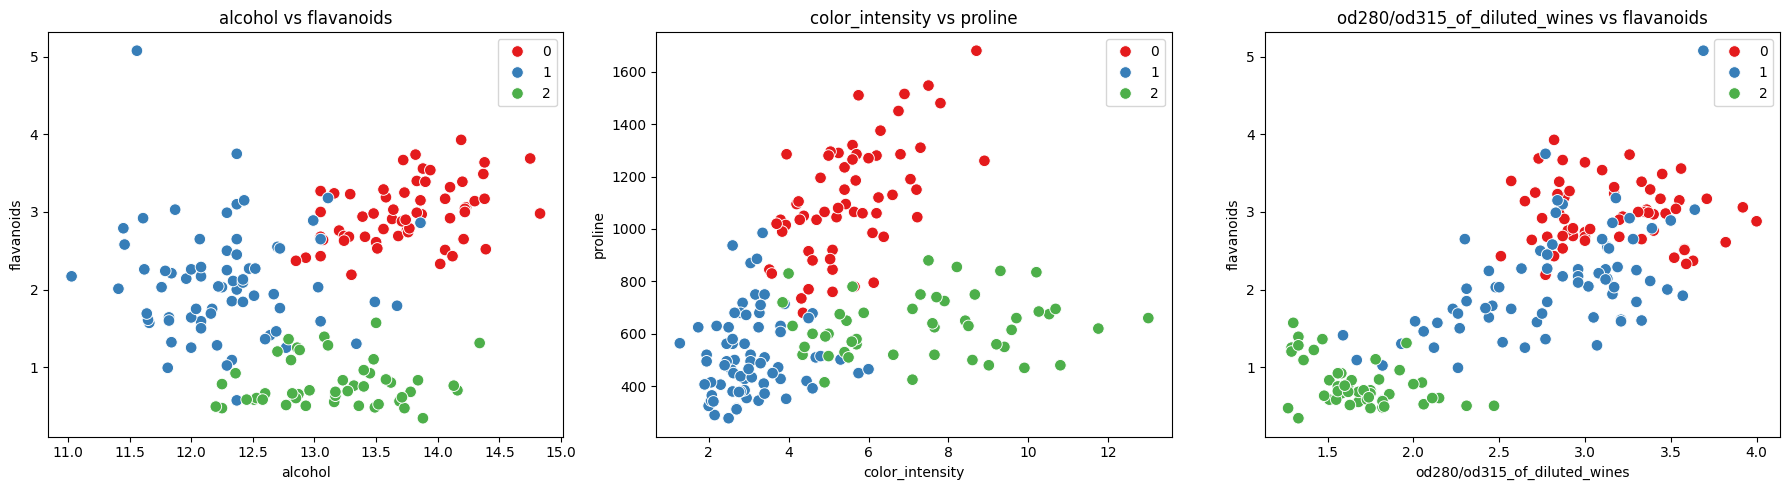

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


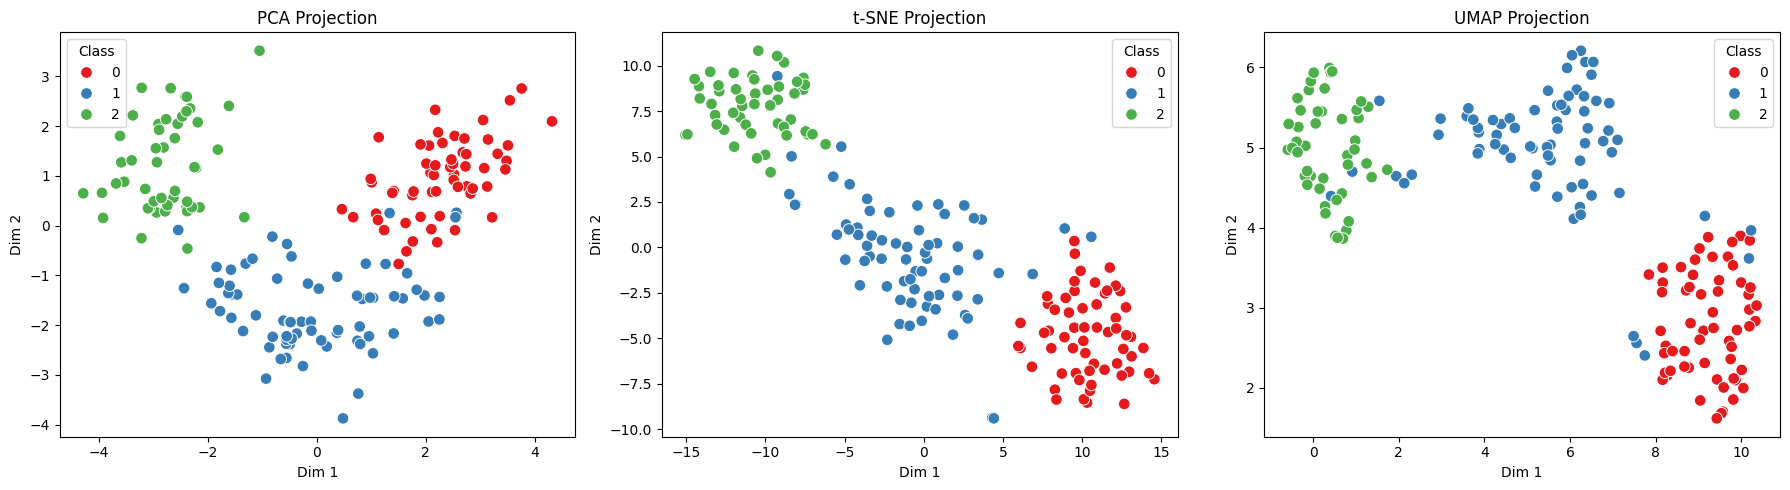

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# -------------------------------------------------
# 1. LOAD WINE DATASET
# -------------------------------------------------
wine = load_wine()

X = wine.data
y = wine.target

df = pd.DataFrame(X, columns=wine.feature_names)

print("Features:")
print(df.columns.tolist())

print("\nDataset shape:", X.shape)


# -------------------------------------------------
# 2. PLOT 3 FEATURE PAIRS
# -------------------------------------------------
pairs = [
    ("alcohol", "flavanoids"),
    ("color_intensity", "proline"),
    ("od280/od315_of_diluted_wines", "flavanoids")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (x_feature, y_feature) in zip(axes, pairs):

    sns.scatterplot(
        x=df[x_feature],
        y=df[y_feature],
        hue=y,
        palette="Set1",
        ax=ax,
        s=70
    )

    ax.set_title(f"{x_feature} vs {y_feature}")
    ax.set_xlabel(x_feature)
    ax.set_ylabel(y_feature)

plt.tight_layout()
plt.show()


# -------------------------------------------------
# 3. STANDARDISE ALL 13 FEATURES
# -------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# -------------------------------------------------
# 4. PCA
# -------------------------------------------------
pca = PCA(n_components=2)
pca_res = pca.fit_transform(X_scaled)


# -------------------------------------------------
# 5. t-SNE
# -------------------------------------------------
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

tsne_res = tsne.fit_transform(X_scaled)


# -------------------------------------------------
# 6. UMAP
# -------------------------------------------------
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    random_state=42
)

umap_res = umap_model.fit_transform(X_scaled)


# -------------------------------------------------
# 7. PLOT PCA, t-SNE AND UMAP
# -------------------------------------------------
results = [
    ("PCA", pca_res),
    ("t-SNE", tsne_res),
    ("UMAP", umap_res)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (title, result) in zip(axes, results):

    plot_df = pd.DataFrame(
        result,
        columns=["Dim 1", "Dim 2"]
    )

    plot_df["Class"] = y

    sns.scatterplot(
        data=plot_df,
        x="Dim 1",
        y="Dim 2",
        hue="Class",
        palette="Set1",
        s=70,
        ax=ax
    )

    ax.set_title(f"{title} Projection")

plt.tight_layout()
plt.show()